# E10 · Designing light with gradients

Design a phase mask by measuring how each parameter affects an image, then replace thousands of separate perturbations with one adjoint calculation.

<!-- course-motivation:start -->
## Why learn this?

**How do you improve a design with thousands of controls?**

You want a phase mask to produce a chosen intensity pattern, but each pixel is a design variable. Perturbing every pixel separately makes each optimization step expensive. You need the sensitivity of one objective to all those variables at once.

**What you gain:** Compute and verify a gradient with an adjoint calculation, use it to improve the pattern, and assess the resulting design without assuming that a lower error proves a global optimum.
<!-- course-motivation:end -->

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Chain rule and gradients:** Apply the multivariable chain rule to one scalar objective. Used here: The gradient measures how each phase pixel changes the image mismatch. [Review: MIT OCW · Chain Rule, Gradient and Directional Derivatives](https://ocw.mit.edu/courses/18-02sc-multivariable-calculus-fall-2010/pages/2.-partial-derivatives/part-b-chain-rule-gradient-and-directional-derivatives/). Use Sessions 32 and 34 for the multivariable chain rule, Session 35 for the gradient, and Session 38 for directional derivatives.
- **Complex inner products:** Use a complex inner product and conjugate transpose. Used here: Moving a linear operator across that inner product produces the adjoint operation. [Review: MIT OCW · Lecture 26: Complex matrices; fast Fourier transform](https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/resources/lecture-26-complex-matrices-fast-fourier-transform/). Focus on complex vectors, conjugate transpose, Hermitian matrices, and unitary matrices. The FFT algorithm at the end is optional here.
- **Fourier transforms and convolution:** Follow a complex field through a forward and inverse Fourier transform. Used here: The core design example uses a unitary Fourier propagation model. [Review: TU Delft · Fourier analysis](https://qiweb.tudelft.nl/aoi/fourieranalysis/fourieranalysis/). Use §4.1 for the transform pair, then §4.2.1–4.2.4 for linearity, scaling, shifts, and convolution. Consult §4.2.7 for two successive transforms.

**Python preparation:** Use complex arrays and compare an analytic derivative with a finite-difference perturbation.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.
- [NumPy · Discrete Fourier Transform](https://numpy.org/doc/stable/reference/routines.fft.html) — Read Implementation details and Normalization; look up fftfreq, fftshift, and ifftshift as they appear in the notebook.

**Developed here:** Derive, check, and use an adjoint phase gradient. Prior knowledge of adjoint optimization is not required.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Derive a real phase gradient through a complex Fourier operator.
- Verify that gradient with central finite differences.
- Explain why adjoints are not generally inverse propagation and why gradients do not guarantee global optimality.

**Model:** 64 × 64 scalar phase-only pupil with a circular fixed amplitude and a unitary Fourier propagation operator. Targets have equal total power. No pixel coupling, material dispersion, noise, or fabrication constraints are included in the browser optimization. The optional Helmholtz example has a lossy boundary layer, explicitly not a PML.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e10_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.11.7 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2


## 1 · Define the forward model and one scalar objective

This core lab combines E02's Fourier propagation with E06's phase mask. It does not
differentiate E09's time-domain Yee solver. Here the design parameters are pupil phases,
the forward map is one unitary FFT, and the scalar objective compares output intensities.
The later optional material-design example switches to a frequency-domain scalar
Helmholtz equation; that also needs its own derivative check and is not the Yee code.

The mask has fixed amplitude A and variable phase φ: u=A exp(iφ). A unitary Fourier
operator P gives v=Pu and intensity I=|v|². We minimize L=½Σ(I−T)²/ΣT².
The target total power equals the input power, a necessary but insufficient feasibility condition.

For a real loss, dL=2 Re⟨q,dv⟩ with q=(I−T)v/ΣT². Move P across the inner product:
b=P†q. Since du=i u dφ, the real phase gradient is 2 Im(u* b).
**Predict:** does computing this gradient require one new optical solve per pixel?

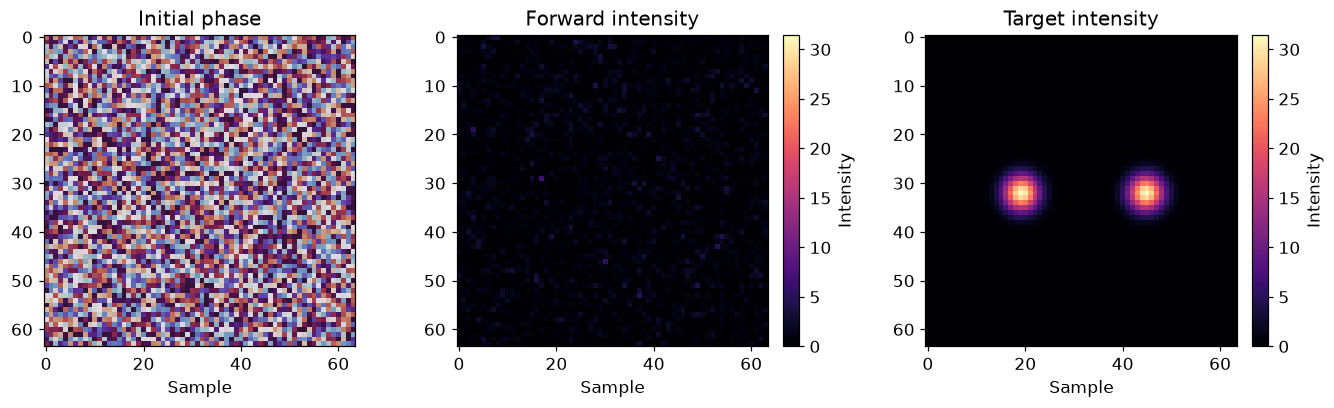

In [2]:
def F(u):
    return np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(u), norm='ortho'))


def FH(v):
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(v), norm='ortho'))


def phase_value(phi, amplitude, target):
    field = F(amplitude * np.exp(1j * phi))
    residual = abs(field)**2 - target
    return 0.5 * np.sum(residual**2) / np.sum(target**2)


def phase_value_grad(phi, amplitude, target):
    pupil = amplitude * np.exp(1j * phi)
    field = F(pupil)
    residual = abs(field)**2 - target
    scale = np.sum(target**2)
    value = 0.5 * np.sum(residual**2) / scale
    error = residual * field / scale  # dJ / d(field*)
    back = FH(error)
    gradient = 2 * np.imag(np.conj(pupil) * back)
    return value, gradient


def phase_step(phi, amplitude, target, max_phase_step=0.6):
    value, gradient = phase_value_grad(phi, amplitude, target)
    peak = np.max(abs(gradient))
    if peak < 1e-14:
        return phi.copy(), value, 0, False
    direction = -gradient / peak
    slope = np.sum(gradient * direction)
    step = max_phase_step
    for trial in range(20):
        candidate = phi + step * direction
        next_value = phase_value(candidate, amplitude, target)
        if np.isfinite(next_value) and next_value <= value + 1e-4 * step * slope:
            return np.remainder(candidate + np.pi, 2*np.pi)-np.pi, next_value, trial + 1, True
        step *= 0.5
    return phi.copy(), value, 20, False


def gaussian_target(n):
    axis = (np.arange(n) - n//2) / n
    yy, xx = np.meshgrid(axis, axis, indexing='ij')
    shape = np.exp(-((xx-.2)**2 + yy**2)/(2*.04**2)) + np.exp(-((xx+.2)**2 + yy**2)/(2*.04**2))
    amplitude = (xx**2+yy**2 < .45**2).astype(float)
    target = shape * np.sum(amplitude**2) / np.sum(shape)
    return amplitude, target



n=64
amplitude,target=gaussian_target(n)
phi=np.random.default_rng(42).uniform(-np.pi,np.pi,(n,n))
value,gradient=phase_value_grad(phi,amplitude,target)
pupil=amplitude*np.exp(1j*phi);field=F(pupil)
assert abs(np.sum(abs(field)**2)-np.sum(amplitude**2))<1e-9
assert abs(gradient.sum())<1e-12 # a global phase cannot change intensity
fig,ax=plt.subplots(1,3,figsize=(12,3.6))
ax[0].imshow(phi,cmap="twilight",vmin=-np.pi,vmax=np.pi)
ax[0].set(title="Initial phase",xlabel="Sample")
# One intensity scale for the target and every output, including the optimized result.
intensity_max=target.max()
for a,img,title in zip(ax[1:],[abs(field)**2,target],["Forward intensity","Target intensity"]):
    image=a.imshow(img,cmap="magma",vmin=0,vmax=intensity_max)
    a.set(title=title,xlabel="Sample")
    fig.colorbar(image,ax=a,fraction=.046,pad=.04,label="Intensity")
show(fig,"01-forward-model")

## 2 · Verify the entire gradient independently

On a small 8×8 problem, perturb each pixel positively and negatively and compare the
central finite difference with the analytic adjoint gradient. Scan the step h: truncation
error dominates for large h and floating-point cancellation for very small h.
Agreement at a useful h checks signs, conjugates, normalization, and FFT ordering.

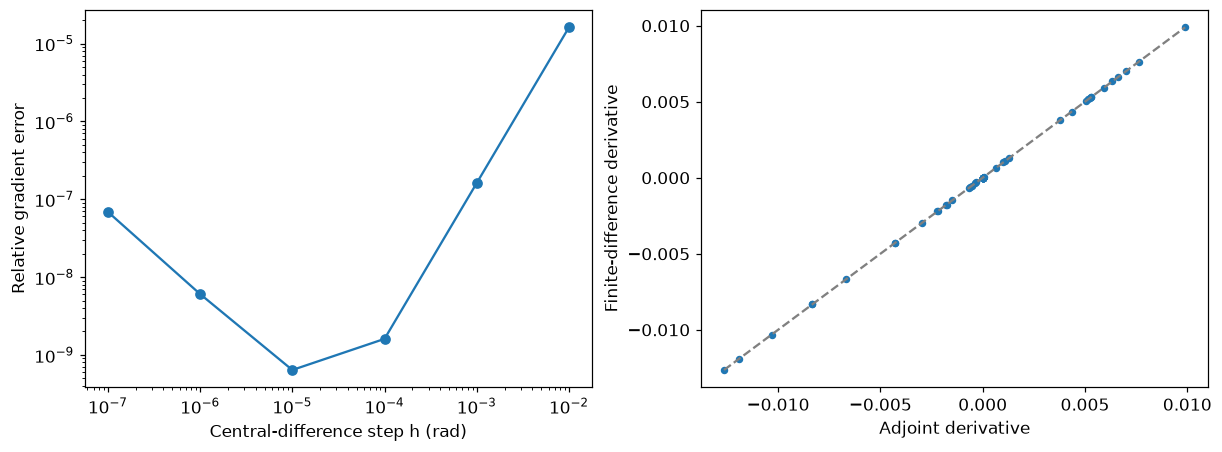

Best all-pixel relative gradient error: 6.404749963832904e-10


In [3]:
a8,t8=gaussian_target(8)
p8=np.random.default_rng(12).uniform(-np.pi,np.pi,(8,8))
_,g8=phase_value_grad(p8,a8,t8)
steps=np.logspace(-2,-7,6);errors=[]
for h in steps:
    fd=np.zeros_like(p8)
    for j in range(p8.size):
        perturb=np.zeros_like(p8);perturb.flat[j]=h
        fd.flat[j]=(phase_value(p8+perturb,a8,t8)-phase_value(p8-perturb,a8,t8))/(2*h)
    errors.append(np.linalg.norm(fd-g8)/np.linalg.norm(g8))
assert min(errors)<1e-7
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].loglog(steps,errors,"o-");ax[0].set(xlabel="Central-difference step h (rad)",ylabel="Relative gradient error")
ax[1].scatter(g8.ravel(),fd.ravel(),s=15);bounds=[g8.min(),g8.max()];ax[1].plot(bounds,bounds,"--",color="gray")
ax[1].set(xlabel="Adjoint derivative",ylabel="Finite-difference derivative")
show(fig,"02-gradient-verification")
print("Best all-pixel relative gradient error:",min(errors))

## 3 · Use descent with a checked step

Backtracking reduces the step until the actual loss satisfies an Armijo decrease condition.
One forward and one adjoint transform give a gradient; rejected trial steps add forward
evaluations. A lower loss is not proof of the global optimum. Compare seeded starts.

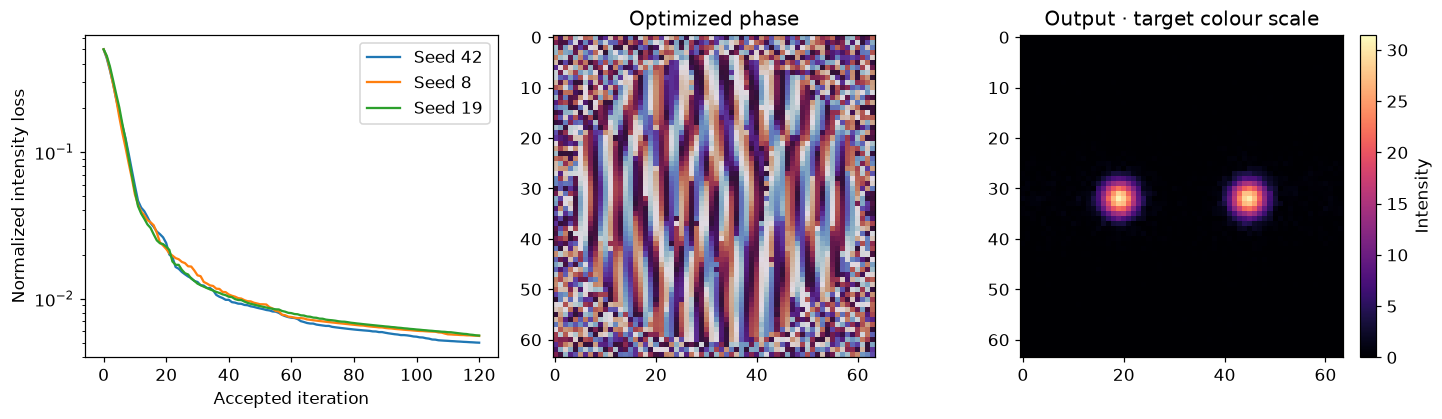

Seeded final losses: [np.float64(0.0050164429845955), np.float64(0.005577984683982654), np.float64(0.005613133323143912)]


In [4]:
histories=[];solutions=[]
for seed in [42,8,19]:
    mask=np.random.default_rng(seed).uniform(-np.pi,np.pi,(n,n))
    history=[phase_value(mask,amplitude,target)]
    for _ in range(120):
        mask,next_value,trials,accepted=phase_step(mask,amplitude,target)
        history.append(next_value)
        if not accepted:break
    assert np.all(np.diff(history)<=1e-13)
    assert history[-1]<.2*history[0]
    histories.append(history);solutions.append(mask)
fig,ax=plt.subplots(1,3,figsize=(13,3.7))
for seed,history in zip([42,8,19],histories):ax[0].semilogy(history,label=f"Seed {seed}")
ax[0].set(xlabel="Accepted iteration",ylabel="Normalized intensity loss");ax[0].legend()
best=solutions[0]
ax[1].imshow(best,cmap="twilight",vmin=-np.pi,vmax=np.pi);ax[1].set(title="Optimized phase")
image=ax[2].imshow(abs(F(amplitude*np.exp(1j*best)))**2,cmap="magma",vmin=0,vmax=intensity_max)
ax[2].set(title="Output · target colour scale")
fig.colorbar(image,ax=ax[2],fraction=.046,pad=.04,label="Intensity")
show(fig,"03-adjoint-optimization")
print("Seeded final losses:",[h[-1] for h in histories])

## 4 · Fabrication constraints change the design problem

Quantize the final phase, or smooth the complex phasor before taking its angle.
Re-evaluate the physical objective after each operation. Postprocessing can spoil a
design; an optimizer that includes these constraints needs their derivatives too.

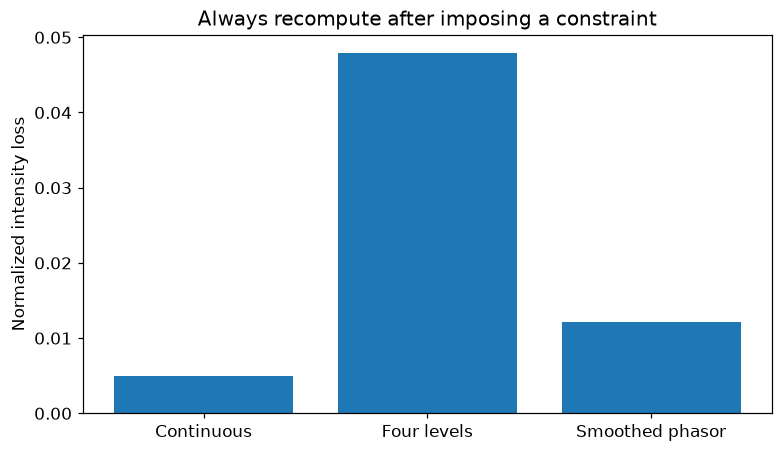

In [5]:
from scipy.ndimage import gaussian_filter
levels=4
quantized=np.round(best/(2*np.pi/levels))*(2*np.pi/levels)
phasor=np.exp(1j*best)
smooth=np.angle(gaussian_filter(phasor.real,.7)+1j*gaussian_filter(phasor.imag,.7))
losses=[phase_value(p,amplitude,target) for p in [best,quantized,smooth]]
fig,ax=plt.subplots(figsize=(7,4));ax.bar(["Continuous","Four levels","Smoothed phasor"],losses)
ax.set(ylabel="Normalized intensity loss",title="Always recompute after imposing a constraint")
show(fig,"04-fabrication-constraints")

## Optional extension · The adjoint of a sparse Helmholtz solve

Let A(ε)E=b with A=∇²+k₀²(ε+iσ), using exp(-iωt). σ is a simple lossy edge layer,
not a PML. For F=Σw|E|², solve A†λ=wE. Then dF/dε=-2k₀² Re(λ*E).
A† is the conjugate transpose; this lossy operator is not Hermitian, and its adjoint
solve is not the inverse of forward propagation. The tiny 12×10 grid is a derivative
demonstration, not a converged device simulation. Boundaries impose zero exterior field.

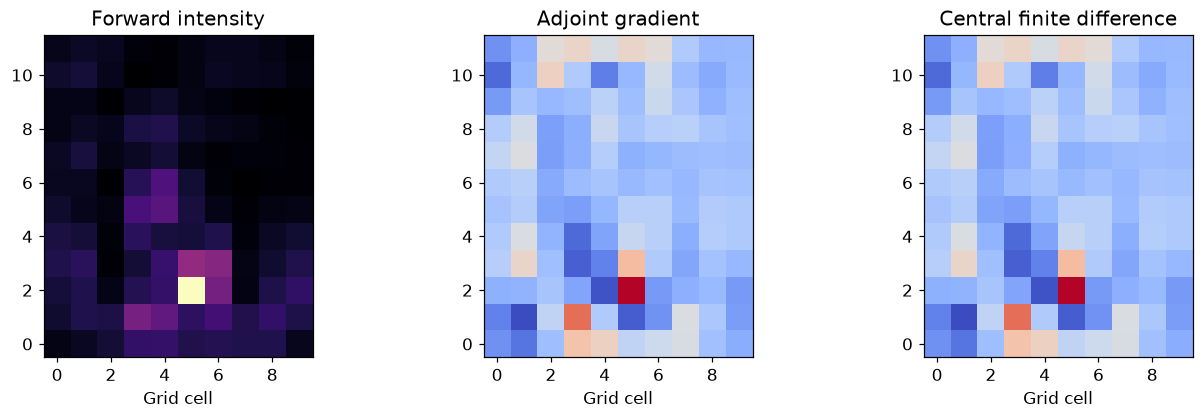

Sparse Helmholtz gradient relative error: 5.020800334884438e-10
Error if conjugation is accidentally omitted: 1.8129195953770494


In [6]:
import scipy.sparse as sp
import scipy.sparse.linalg as sla
def helmholtz_fixture(nx=12, ny=10):
    h, k0 = .2, 2*np.pi/1.55
    def d2(n):
        return sp.diags([np.ones(n-1), -2*np.ones(n), np.ones(n-1)], [-1,0,1], format='csc') / h**2
    laplacian = sp.kron(d2(nx), sp.eye(ny)) + sp.kron(sp.eye(nx), d2(ny))
    xx, yy = np.meshgrid(np.arange(nx), np.arange(ny), indexing='ij')
    edge_dist = np.minimum.reduce([xx, yy, nx-1-xx, ny-1-yy])
    sigma = .08 + .4 * np.clip((3-edge_dist)/3, 0, 1)**2
    source = np.zeros((nx,ny), complex)
    source[2, ny//2] = 1 + .3j
    weight = np.zeros((nx,ny))
    weight[-3, 2:-2] = 1
    def evaluate(eps, gradient=False):
        A = (laplacian + sp.diags(k0**2 * (eps + 1j*sigma).ravel())).tocsc()
        lu = sla.splu(A)
        field = lu.solve(source.ravel())
        value = np.sum(weight.ravel() * abs(field)**2)
        if not gradient: return value
        q = weight.ravel() * field  # dF / d(field*)
        adjoint = lu.solve(q, trans='H')
        grad = -2 * k0**2 * np.real(np.conj(adjoint) * field)
        transpose_adjoint = lu.solve(np.conj(q), trans='T')
        grad_T = -2*k0**2 * np.real(transpose_adjoint * field)
        wrong_grad = -2*k0**2 * np.real(adjoint * field)
        return value, grad.reshape(nx,ny), grad_T.reshape(nx,ny), wrong_grad.reshape(nx,ny), A, field, adjoint
    return evaluate, (nx,ny)



evaluate,shape=helmholtz_fixture()
eps=np.random.default_rng(17).uniform(1.6,2.4,shape)
merit,grad,grad_T,wrong,A,field,adjoint=evaluate(eps,True)
h=1e-5;fd=np.zeros(shape)
for j in range(eps.size):
    perturb=np.zeros(shape);perturb.flat[j]=h
    fd.flat[j]=(evaluate(eps+perturb)-evaluate(eps-perturb))/(2*h)
relative=np.linalg.norm(grad-fd)/np.linalg.norm(fd)
assert relative<1e-6
assert np.max(abs(grad-grad_T))<1e-12
fig,ax=plt.subplots(1,3,figsize=(12,3.7))
for a,img,title in zip(ax,[abs(field.reshape(shape))**2,grad,fd],["Forward intensity","Adjoint gradient","Central finite difference"]):
    a.imshow(img,origin="lower",cmap="magma" if "intensity" in title else "coolwarm");a.set(title=title,xlabel="Grid cell")
show(fig,"05-helmholtz-adjoint")
print("Sparse Helmholtz gradient relative error:",relative)
print("Error if conjugation is accidentally omitted:",np.linalg.norm(wrong-fd)/np.linalg.norm(fd))

## A short lab report

**1. Check derivatives.** Compare an analytic phase gradient with central differences at several perturbation sizes.

**2. Count actual work.** Report gradient evaluations and extra forward trials for two maximum step sizes.

**3. Test the manufactured design.** Quantize the final phase and re-evaluate the unchanged objective and intensity normalization.

### Worked reasoning

**Check derivatives.** Look for an intermediate step-size range where truncation and roundoff are both small; compare relative and absolute errors.

**Count actual work.** One forward plus one adjoint produces a gradient for one objective. Backtracking and validation add separate evaluations.

**Test the manufactured design.** Fabrication projection can worsen performance. A model-aware optimization can include such constraints, but a continuous-mask result alone is insufficient.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [Steven G. Johnson · Notes on adjoint methods](https://math.mit.edu/~stevenj/18.336/adjoint.pdf)
- [SciPy · Sparse factorization solve conventions](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.linalg.SuperLU.solve.html)
- [NumPy · Fourier transforms and normalization](https://numpy.org/doc/stable/reference/routines.fft.html)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [7]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 5 figures in e10_figures.zip


/tmp/optics-notebooks-w00ghsb7/E10/e10_figures.zip